<a href="https://colab.research.google.com/github/Gobishangar1/CDAZZDEV-MLE-GobishangarVijayendran/blob/main/task1_financial/notebooks/task1_equity_research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: LLM-Powered Equity Research Assistant

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Gobishangar1/CDAZZDEV-MLE-GobishangarVijayendran/blob/main/task1_financial/notebooks/task1_equity_research.ipynb)

**Candidate:** Gobishangar Vijayendran · **Ticker:** NVDA (liquid, with plenty of news)

This notebook runs every graded part of Task 1, in rubric order. All logic lives in the
`equity_research` package; the notebook only calls it and shows the results.

| Part | Section of this notebook |
|---|---|
| 1A OHLCV fetch, indicators, news, summary, robustness | Sections 1-6 |
| 1B per-headline JSON, signal reasoning, validation, prompts | Sections 7-12 |
| Bonus report | Section 13 |

Design: a fixed LangGraph workflow (not an agent). **Python does the maths; the LLM only judges.**

## 0. Setup

In [4]:
import os, sys

if "google.colab" in sys.modules:                       # Colab: clone the repo and install
    if not os.path.exists("CDAZZDEV-MLE-GobishangarVijayendran"):
        !git clone -q https://github.com/Gobishangar1/CDAZZDEV-MLE-GobishangarVijayendran.git
    %cd CDAZZDEV-MLE-GobishangarVijayendran/task1_financial
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":       # local Jupyter started inside notebooks/
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

/content/CDAZZDEV-MLE-GobishangarVijayendran/task1_financial/CDAZZDEV-MLE-GobishangarVijayendran/task1_financial/CDAZZDEV-MLE-GobishangarVijayendran/task1_financial
Working directory: /content/CDAZZDEV-MLE-GobishangarVijayendran/task1_financial/CDAZZDEV-MLE-GobishangarVijayendran/task1_financial/CDAZZDEV-MLE-GobishangarVijayendran/task1_financial


In [5]:
# The Groq key comes from Colab Secrets (key icon on the left) or from the environment.
# It is NEVER printed and NEVER written to a file.
from equity_research.config import load_colab_secret, require_groq_key, setup_logging

loaded = load_colab_secret("GROQ_API_KEY")
require_groq_key()
print("GROQ_API_KEY available:", True, "| loaded from Colab Secrets:", loaded)

setup_logging()        # our logs at INFO; validation failures appear as WARNING lines
TICKER = "NVDA"

GROQ_API_KEY available: True | loaded from Colab Secrets: True


## 1. Configuration: no magic numbers
Every window, threshold and weight is a named constant in `config.py`, each with a one-line reason.

In [6]:
import pandas as pd
from equity_research.config import constants_table
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(constants_table(), columns=["constant", "value"])

,constant,value
0,HISTORY_YEARS,2
1,WARMUP_CALENDAR_DAYS,300
2,TRADING_DAYS_PER_YEAR,252
3,TICKER_PATTERN,"^[A-Z0-9.\-^]{1,10}$"
4,PROBE_PERIOD,5d
...,...,...
56,MAX_CONCURRENCY,3
57,LOG_TRUNCATE,200
58,CHART_DAYS,252
59,CHART_DPI,150


## 2. Task 1A: OHLCV data (at least two years, no hard-coded dates)
Start date = today − 2 years − 300 days of warm-up (so SMA-200 has a value on day 1 of the 2-year window).
Prices are split- and dividend-adjusted.

In [7]:
from equity_research.market_data import compute_start_dates, fetch_prices

df_raw, price_warnings = fetch_prices(TICKER)
fetch_start, display_start = compute_start_dates(pd.Timestamp.today())
in_window = df_raw[df_raw.index >= display_start]

print(f"Fetched from {df_raw.index[0].date()} to {df_raw.index[-1].date()}: {len(df_raw)} trading days")
print(f"2-year window from {display_start.date()}: {len(in_window)} trading days "
      f"({(in_window.index[-1] - in_window.index[0]).days / 365.25:.2f} years)")
print("Data-quality warnings:", price_warnings or "none")
assert (in_window.index[-1] - in_window.index[0]).days >= 365 * 2 - 7
df_raw.tail()

09:05:34 INFO    equity_research.market_data | prices_ok ticker=NVDA rows=705 first=2023-12-18 last=2026-10-09


Fetched from 2023-12-18 to 2026-10-09: 705 trading days
2-year window from 2024-10-11: 500 trading days (1.99 years)
Data-quality warnings: none


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-05,236.089996,240.100006,235.149994,238.899994,127171500
2026-10-06,242.100006,243.369995,238.929993,239.240005,101701900
2026-10-07,237.690002,239.080002,236.380005,237.470001,81772400
2026-10-08,234.919998,237.070007,229.850006,230.479996,118697400
2026-10-09,233.839996,233.919998,229.110001,229.279999,84470000


## 3. Task 1A: technical indicators from first principles (no TA-Lib)
SMA-50, SMA-200, RSI-14 (Wilder), MACD (12, 26, 9), Bollinger Bands (20, 2σ, population std).

In [8]:
from equity_research.indicators import add_indicators

df = add_indicators(df_raw)
cols = ["Close", "SMA_50", "SMA_200", "RSI_14", "MACD", "MACD_signal", "MACD_hist",
        "BB_lower", "BB_middle", "BB_upper", "BB_pctB"]
df[cols].tail().round(3)

,Close,SMA_50,SMA_200,RSI_14,MACD,MACD_signal,MACD_hist,BB_lower,BB_middle,BB_upper,BB_pctB
Date,,,,,,,,,,,
2026-10-05,238.90,218.765,200.687,67.010,4.222,3.019,1.203,210.310,224.188,238.066,1.030
2026-10-06,239.24,219.624,201.031,67.272,4.735,3.362,1.373,209.524,224.876,240.228,0.968
2026-10-07,237.47,220.438,201.349,64.407,4.942,3.678,1.263,209.299,225.579,241.858,0.865
2026-10-08,230.48,221.251,201.599,54.531,4.490,3.840,0.649,210.124,226.185,242.245,0.634
2026-10-09,229.28,221.940,201.829,53.027,3.989,3.870,0.119,211.044,226.734,242.424,0.581


**Proof of accuracy:** the test suite checks hand-computed values (SMA, EMA, Wilder RSI), an independent
loop implementation of EMA, MACD identities, Bollinger against numpy's population std, and edge cases
(flat prices, only gains, too little data). The full suite runs offline in a few seconds.

In [9]:
!python -m pytest -q tests

........................................................................ [ 75%]
.......................                                                  [100%]


## 4. Task 1A: chart preview (last 12 months)

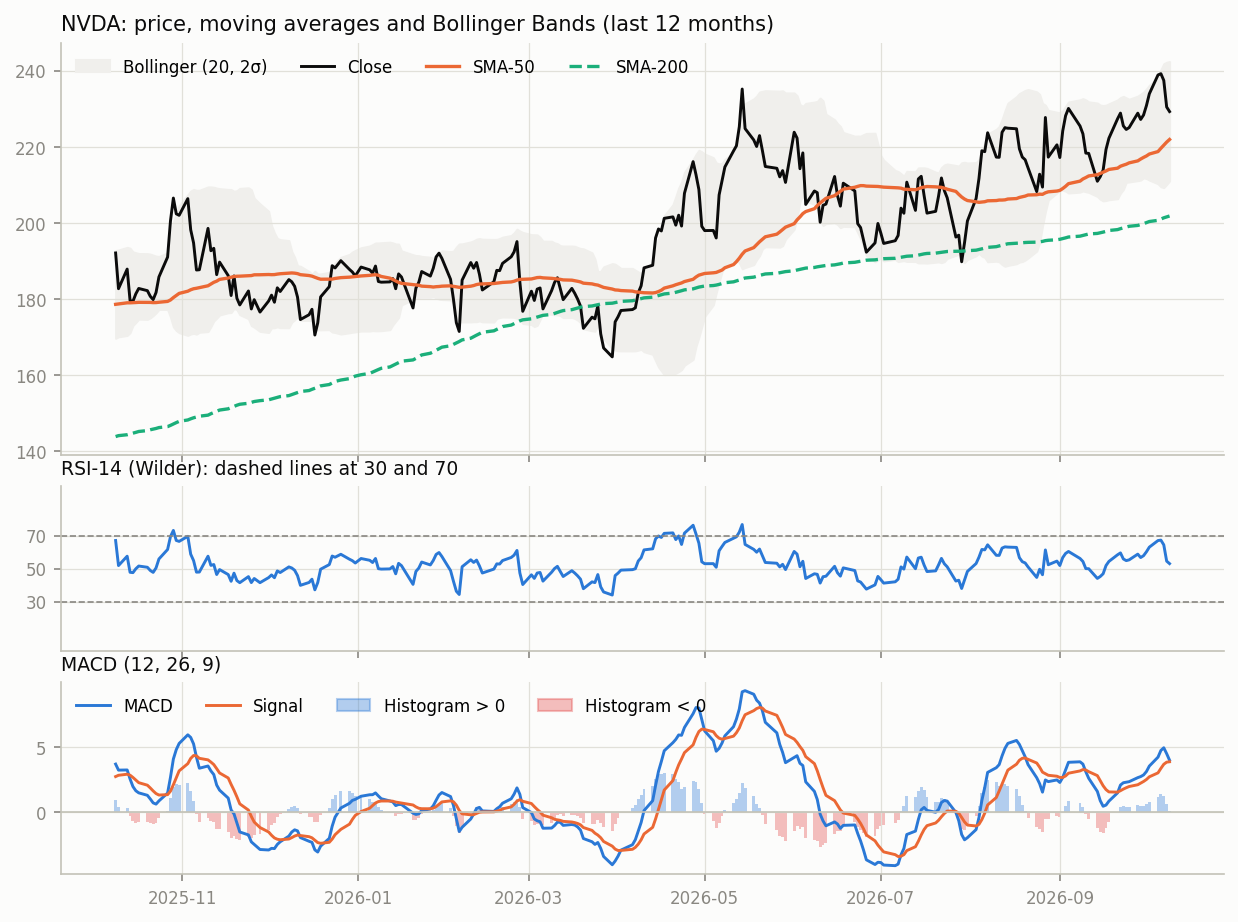

In [10]:
from pathlib import Path
from IPython.display import Image, display
from equity_research.report import make_chart

Path("outputs").mkdir(exist_ok=True)
display(Image(filename=str(make_chart(df, TICKER, Path("outputs") / "preview_chart.png"))))

## 5. Task 1A: news headlines (at least ten, free sources)
Provider chain: yfinance news → Yahoo Finance RSS → Google News RSS, de-duplicated, newest first.
Free feeds mix in general market stories, so headlines that **name the ticker or the company** come first;
general headlines are only added to reach ten, and that is reported as a warning.

In [11]:
from equity_research.market_data import fetch_info
from equity_research.news import fetch_news

headlines, news_warnings = fetch_news(TICKER, fetch_info(TICKER).get("longName"))
print(f"{len(headlines)} unique headlines, {sum(h['relevant'] for h in headlines)} about {TICKER} "
      f"| warnings: {news_warnings or 'none'}")
pd.DataFrame(headlines)[["published_at", "publisher", "source", "relevant", "title"]]

09:05:47 WARNING equity_research.news | yfinance_news_empty ticker=NVDA tab=news
09:05:47 WARNING equity_research.news | yfinance_news_empty ticker=NVDA tab=all
09:05:47 INFO    equity_research.news | news_provider name=yfinance items=0 unique_total=0 relevant_total=0
09:05:48 INFO    equity_research.news | news_provider name=yahoo_rss items=20 unique_total=20 relevant_total=4
09:05:49 INFO    equity_research.news | news_provider name=google_news items=100 unique_total=119 relevant_total=103


15 unique headlines, 15 about NVDA | warnings: ['News source yfinance returned no items']


,published_at,publisher,source,relevant,title
0,2026-10-11 07:58:02+00:00,fool.com,yahoo_rss,True,TSMC Reports Oct. 15. It's the Best Early Read on Nvidia's Next Quarter.
1,2026-10-11 07:47:33+00:00,MarketBeat,google_news,True,NVIDIA Corporation $NVDA Shares Bought by Canada Pension Plan Investment Board - MarketBeat
2,2026-10-11 07:45:43+00:00,MarketBeat,google_news,True,NVIDIA Corporation $NVDA Stock Position Raised by Castleark Management LLC - MarketBeat
3,2026-10-11 07:29:15+00:00,MarketBeat,google_news,True,NVIDIA Corporation $NVDA Stock Position Decreased by AFT Forsyth & Company Inc. - MarketBeat
4,2026-10-11 06:57:52+00:00,tikr.com,yahoo_rss,True,"Nvidia Weighs Buying Reflection AI, the $25 Billion Open-Weight Model Startup It Already Backs"
5,2026-10-11 00:57:01+00:00,fool.com,yahoo_rss,True,Cerebras Is About as Big as Nvidia's Data Center Business Was Nearly a Decade Ago. The Similarities Mostly End There.
6,2026-10-10 22:11:26+00:00,finance.yahoo.com,yahoo_rss,True,Amazon (AMZN) Wants Investors to Finance $8 Billion of Nvidia Chips. Is AI Spending Getting Too Heavy?
7,2026-10-10 18:20:21+00:00,Benzinga,google_news,True,"Nvidia-Backed Neoclouds Face a Test as IREN, CoreWeave and Nebius Stocks Slide - Benzinga"
8,2026-10-10 17:10:39+00:00,Yahoo Finance,google_news,True,"Nvidia (NVDA) More Than Doubled Revenue, Yet Its Multiple Sits Below History. Bargain or Warning? - Yahoo Finance"
9,2026-10-10 16:54:15+00:00,Benzinga,google_news,True,SoundHound AI Stock: Why This Nvidia-Backed AI Voice Giant Is in a Freefall - Benzinga


## 6. Task 1A: the summary dictionary
Current price, 52-week high/low (from the High/Low columns), P/E (Yahoo trailing → price/EPS if EPS > 0 →
None), YTD return (vs the last close of the previous year), and a rule-based momentum signal.

In [12]:
from pprint import pprint
from equity_research.analysis import build_summary, indicator_snapshot, momentum_signal
from equity_research.market_data import fetch_info

info = fetch_info(TICKER)
snapshot = indicator_snapshot(df)
summary = build_summary(TICKER, df, info, momentum_signal(snapshot)).model_dump()
pprint(summary, sort_dicts=False)

{'ticker': 'NVDA',
 'company_name': 'NVIDIA Corporation',
 'currency': 'USD',
 'as_of': '2026-10-09',
 'current_price': 229.28,
 'high_52w': 243.37,
 'low_52w': 163.9,
 'pct_from_52w_high': -5.79,
 'pe_ratio': 28.99,
 'pe_source': 'trailingPE',
 'ytd_return_pct': 23.23,
 'ytd_base': 'prior_year_close',
 'momentum': {'label': 'strong_bullish',
              'score': 0.621,
              'components': {'long_trend': 1.0,
                             'short_trend': 1.0,
                             'macd': 0.5,
                             'rsi': 0.15,
                             'bollinger': 0.16},
              'missing': []}}


## 7. Task 1B: the LangGraph workflow
Parallel fetches → `Send()` fan-out (one LLM call per headline) → joins → signal with a validation retry
loop → rule-based fallback → report. Nodes write state; routers only read it.

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	validate_input(validate_input)
	fetch_prices(fetch_prices)
	fetch_info(fetch_info)
	fetch_news(fetch_news)
	dispatch_headlines(dispatch_headlines)
	compute_indicators(compute_indicators)
	build_summary(build_summary)
	classify_headline(classify_headline)
	aggregate_sentiment(aggregate_sentiment)
	build_context(build_context)
	generate_signal(generate_signal)
	rule_fallback(rule_fallback)
	render_report(render_report)
	finalize(finalize)
	error_report(error_report)
	__end__([<p>__end__</p>]):::last
	__start__ --> validate_input;
	aggregate_sentiment --> build_context;
	build_context -.-> error_report;
	build_context -.-> generate_signal;
	build_summary --> build_context;
	classify_headline --> aggregate_sentiment;
	compute_indicators --> build_summary;
	dispatch_headlines -.-> aggregate_sentiment;
	dispatch_headlines -.-> classify_headline;
	fetch_info --> build_summary;
	fetch_info --> disp

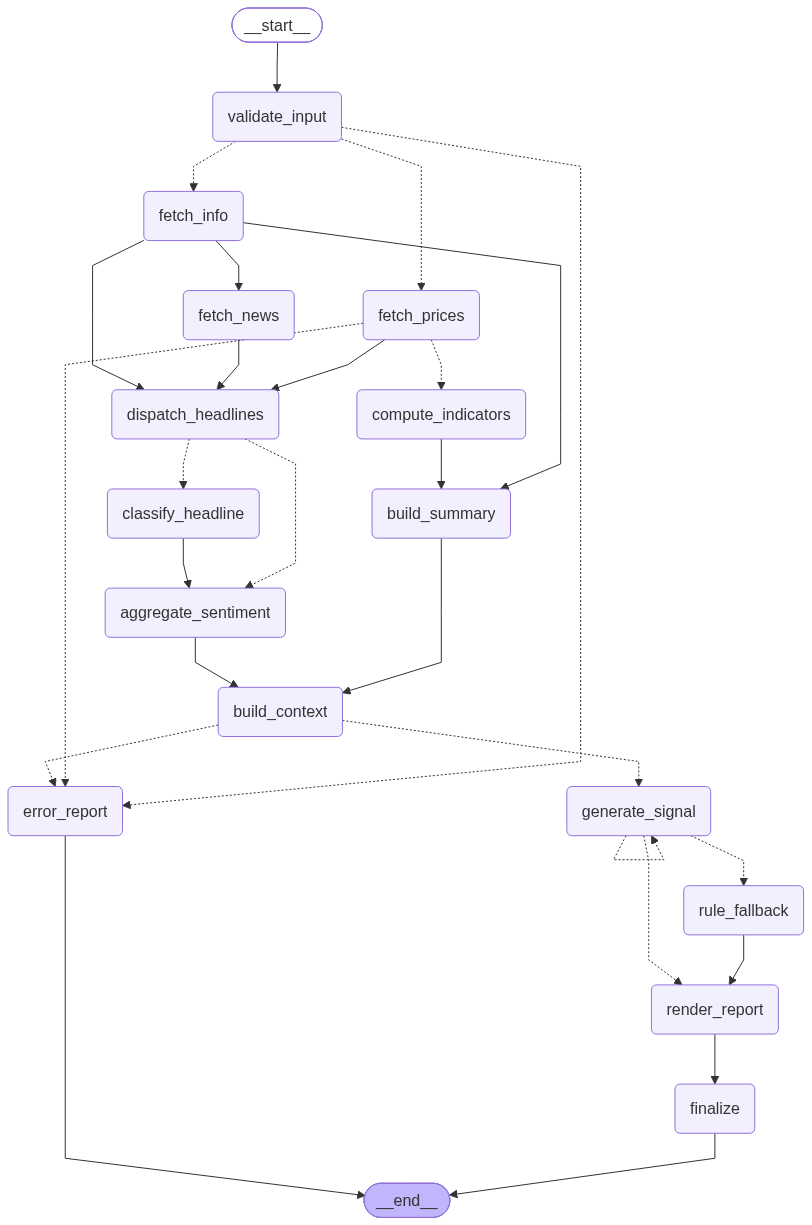

In [13]:
from equity_research.graph import build_graph, run_pipeline

graph = build_graph(None, None)
print(graph.get_graph().draw_mermaid())
try:                                    # the PNG uses an online renderer; the text above always works
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG render skipped:", type(exc).__name__)

### Run the whole pipeline
Each line shows a node finishing, with the elapsed time. Headline calls are rate-limited for the Groq free tier.

In [14]:
result = run_pipeline(TICKER, output_dir="outputs")
print("\nstatus:", result["status"], "| signal source:", result["signal_source"])

[   0.1s] validate_input


09:05:54 INFO    equity_research.market_data | prices_ok ticker=NVDA rows=705 first=2023-12-18 last=2026-10-09


[   0.4s] fetch_prices
[   0.6s] fetch_info
[   0.6s] compute_indicators


09:05:55 WARNING equity_research.news | yfinance_news_empty ticker=NVDA tab=news
09:05:56 WARNING equity_research.news | yfinance_news_empty ticker=NVDA tab=all
09:05:56 INFO    equity_research.news | news_provider name=yfinance items=0 unique_total=0 relevant_total=0
09:05:56 INFO    equity_research.news | news_provider name=yahoo_rss items=20 unique_total=20 relevant_total=4
09:05:56 INFO    equity_research.news | news_provider name=google_news items=100 unique_total=119 relevant_total=103


[   2.5s] fetch_news
[   2.5s] dispatch_headlines
[   2.5s] build_summary
[   7.9s] classify_headline
[  12.9s] classify_headline
[  17.9s] classify_headline
[  23.2s] classify_headline
[  27.9s] classify_headline
[  33.1s] classify_headline
[  38.1s] classify_headline
[  43.1s] classify_headline
[  48.2s] classify_headline
[  53.1s] classify_headline
[  58.1s] classify_headline
[  63.1s] classify_headline
[  68.0s] classify_headline
[  73.2s] classify_headline
[  78.1s] classify_headline
[  78.1s] aggregate_sentiment
[  78.1s] build_context


09:07:19 INFO    equity_research.graph | signal_ok attempt=1 signal=BUY


[  85.6s] generate_signal


09:07:20 INFO    equity_research.report | report_written dir=outputs/NVDA_2026-10-09


[  86.3s] render_report
[  86.3s] finalize

Trace: 86.27s | 16 LLM calls (0 API errors, 0 failed validations) | tokens in 6,112 / out 2,315 | models ['openai/gpt-oss-120b', 'openai/gpt-oss-20b']

status: ok | signal source: llm


### Trace of this run (`trace.jsonl`)
One event per node and per LLM call: which model answered (20B, or the 120B fallback), latency, tokens,
and every validation result. Saved next to `run.json`.

In [15]:
import json
print(json.dumps(result["trace_summary"], indent=2))
events = [json.loads(line) for line in open(result["report_paths"]["trace"], encoding="utf-8")]
llm_calls = pd.DataFrame([e for e in events if e["kind"] == "llm_call"])
llm_calls[["t_s", "purpose", "attempt", "model", "latency_ms", "input_tokens", "output_tokens", "ok", "detail"]]

{
  "wall_time_s": 86.27,
  "llm_calls": 16,
  "llm_api_errors": 0,
  "validation_failures": 0,
  "input_tokens": 6112,
  "output_tokens": 2315,
  "models": [
    "openai/gpt-oss-120b",
    "openai/gpt-oss-20b"
  ],
  "llm_latency_s": 219.26,
  "nodes_ms": {
    "classify_headline": 211790,
    "generate_signal": 7479,
    "fetch_news": 1886,
    "render_report": 676,
    "fetch_info": 487,
    "fetch_prices": 305,
    "validate_input": 133,
    "compute_indicators": 10,
    "build_summary": 4,
    "dispatch_headlines": 0,
    "aggregate_sentiment": 0,
    "build_context": 0,
    "finalize": 0
  }
}


,t_s,purpose,attempt,model,latency_ms,input_tokens,output_tokens,ok,detail
0,7.912,headline,1,openai/gpt-oss-20b,5391,359,88,True,TSMC Reports Oct. 15. It's the Best Early Read on Nvidia's Next Quarter.
1,12.915,headline,1,openai/gpt-oss-20b,10392,356,72,True,NVIDIA Corporation $NVDA Shares Bought by Canada Pension Plan Investment Board -
2,17.874,headline,1,openai/gpt-oss-20b,15353,356,120,True,NVIDIA Corporation $NVDA Stock Position Raised by Castleark Management LLC - Mar
3,23.188,headline,1,openai/gpt-oss-20b,5313,365,82,True,Cerebras Is About as Big as Nvidia's Data Center Business Was Nearly a Decade Ag
4,27.902,headline,1,openai/gpt-oss-20b,4714,363,100,True,Amazon (AMZN) Wants Investors to Finance $8 Billion of Nvidia Chips. Is AI Spend
5,33.115,headline,1,openai/gpt-oss-20b,5212,366,92,True,"Nvidia-Backed Neoclouds Face a Test as IREN, CoreWeave and Nebius Stocks Slide -"
6,38.053,headline,1,openai/gpt-oss-20b,4938,367,82,True,"Nvidia (NVDA) More Than Doubled Revenue, Yet Its Multiple Sits Below History. Ba"
7,43.123,headline,1,openai/gpt-oss-20b,5069,363,93,True,SoundHound AI Stock: Why This Nvidia-Backed AI Voice Giant Is in a Freefall - Be
8,48.248,headline,1,openai/gpt-oss-20b,35333,362,118,True,"Nvidia Weighs Buying Reflection AI, the $25 Billion Open-Weight Model Startup It"
9,53.130,headline,1,openai/gpt-oss-20b,45218,361,82,True,NVIDIA Corporation $NVDA Stock Position Decreased by AFT Forsyth & Company Inc.


## 8. Task 1B: per-headline structured JSON + aggregate score
Each headline → one LLM call → JSON validated by Pydantic (`headline`, `sentiment`, `confidence`,
`brief_reason`). Invalid replies are logged with the raw text and retried once with the error message.

Aggregate: **S = Σ wᵢ·cᵢ·sᵢ / Σ wᵢ·cᵢ**, with s = +1 / 0 / −1, c = confidence,
w = 0.5^(age_days / 3) (3-day half-life). Neutral headlines stay in the denominator, so mostly-neutral
news gives a score near 0.

In [16]:
import json
per_headline = pd.DataFrame(result["headline_results"])
print("Example of one validated JSON object:")
print(json.dumps({k: result["headline_results"][0][k] for k in ["headline", "sentiment", "confidence", "brief_reason"]},
                 indent=2))
print("\nFailures (logged, run continued):", result["headline_failures"] or "none")
print("\nAggregate:", json.dumps(result["sentiment"], indent=2))
per_headline[["headline", "sentiment", "confidence", "brief_reason", "publisher", "published_at"]]

Example of one validated JSON object:
{
  "headline": "TSMC Reports Oct. 15. It's the Best Early Read on Nvidia's Next Quarter.",
  "sentiment": "positive",
  "confidence": 0.9,
  "brief_reason": "A favorable TSMC report suggests strong upcoming Nvidia earnings, likely boosting its share price."
}

Failures (logged, run continued): none

Aggregate: {
  "score": 0.347,
  "label": "positive",
  "counts": {
    "positive": 5,
    "neutral": 9,
    "negative": 1
  },
  "agreement": 0.6,
  "coverage": 1.0,
  "n_valid": 15
}


,headline,sentiment,confidence,brief_reason,publisher,published_at
0,TSMC Reports Oct. 15. It's the Best Early Read on Nvidia's Next Quarter.,positive,0.9,"A favorable TSMC report suggests strong upcoming Nvidia earnings, likely boosting its share price.",fool.com,2026-10-11T07:58:02+00:00
1,NVIDIA Corporation $NVDA Shares Bought by Canada Pension Plan Investment Board - MarketBeat,positive,0.9,"Large institutional purchase signals confidence, likely boosting the stock.",MarketBeat,2026-10-11T07:47:33+00:00
2,NVIDIA Corporation $NVDA Stock Position Raised by Castleark Management LLC - MarketBeat,neutral,0.6,A position change by an investment manager is generally neutral unless it signals a major shift in outlook.,MarketBeat,2026-10-11T07:45:43+00:00
3,NVIDIA Corporation $NVDA Stock Position Decreased by AFT Forsyth & Company Inc. - MarketBeat,neutral,0.6,A position change by a single firm is not a clear catalyst for NVDA’s price movement.,MarketBeat,2026-10-11T07:29:15+00:00
4,"Nvidia Weighs Buying Reflection AI, the $25 Billion Open-Weight Model Startup It Already Backs",positive,0.9,"Acquisition of a high‑valued AI startup signals growth and expansion, likely boosting investor sentiment.",tikr.com,2026-10-11T06:57:52+00:00
5,Cerebras Is About as Big as Nvidia's Data Center Business Was Nearly a Decade Ago. The Similarities Mostly End There.,neutral,0.6,Mentions competitor size but no direct impact on Nvidia’s performance or outlook.,fool.com,2026-10-11T00:57:01+00:00
6,Amazon (AMZN) Wants Investors to Finance $8 Billion of Nvidia Chips. Is AI Spending Getting Too Heavy?,positive,0.7,"Amazon seeking funding for Nvidia chips signals strong demand, likely boosting NVDA’s share price.",finance.yahoo.com,2026-10-10T22:11:26+00:00
7,"Nvidia-Backed Neoclouds Face a Test as IREN, CoreWeave and Nebius Stocks Slide - Benzinga",neutral,0.6,The headline focuses on Neoclouds and other stocks; no direct impact on NVDA’s share price is evident.,Benzinga,2026-10-10T18:20:21+00:00
8,"Nvidia (NVDA) More Than Doubled Revenue, Yet Its Multiple Sits Below History. Bargain or Warning? - Yahoo Finance",neutral,0.6,"Revenue growth is good, but valuation concerns suggest mixed market reaction.",Yahoo Finance,2026-10-10T17:10:39+00:00
9,SoundHound AI Stock: Why This Nvidia-Backed AI Voice Giant Is in a Freefall - Benzinga,negative,0.8,"The headline indicates a decline in a company backed by Nvidia, suggesting negative sentiment for Nvidia’s stock.",Benzinga,2026-10-10T16:54:15+00:00


## 9. Task 1B: facts and conflicts given to the LLM
Code turns numbers into **facts** (direction, distance, zone, change over time) and lists **conflicts**
(signals that disagree). The prompt requires the LLM to resolve every conflict, so it must reason about
combinations instead of echoing values, and it never has to do arithmetic.

In [17]:
print("FACTS:")
for f in result["facts"]:
    print(" -", f)
print("\nCONFLICTS:")
for c in result["conflicts"] or ["none"]:
    print(" -", c)

FACTS:
 - Close 229.28 is 3.3% above SMA-50 (221.94).
 - Close is 13.6% above SMA-200 (201.83).
 - SMA-50 is above SMA-200: long-term trend is up.
 - Last moving-average cross: golden cross 323 trading days ago.
 - MACD histogram is positive (+0.12) and shrinking toward zero (bullish momentum fading).
 - MACD line is above its signal line and above zero.
 - RSI-14 is 53.0 (neutral zone); it was 55.3 ten trading days ago.
 - Bollinger %B is 0.58 (price inside the bands).
 - Price is 5.8% below its 52-week high (243.37); 52-week low is 163.90.
 - Year-to-date return is +23.2%.
 - Trailing P/E is 29.0.
 - News sentiment is +0.35 (positive) from 15 headlines; agreement 60%, coverage 100%.

CONFLICTS:
 - Trend is up, but MACD momentum is fading or negative.


## 10. Task 1B: the Buy / Hold / Sell signal and its validation
Two levels: **schema** (Pydantic: enum, 0-1 confidence, 3-5 sentences, ≥ 2 drivers) and **meaning**
(no invented numbers, ≥ 2 indicator groups, conflicts addressed, confidence ≤ 0.75 when conflicts exist,
anti-echo). Up to 3 attempts with feedback, then a rule-based fallback.

In [18]:
print(json.dumps(result["signal"], indent=2))
print("\nSource:", result["signal_source"])
pd.DataFrame([{"attempt": h["attempt"], "passed": not h["problems"], "problems": "; ".join(h["problems"]) or "-"}
              for h in result["signal_history"]])

{
  "signal": "BUY",
  "confidence": 0.7,
  "justification": "The price is 3.3% above the SMA\u201150 and 13.6% above the SMA\u2011200, confirming a strong uptrend while the SMA\u201150 remains above the SMA\u2011200, which reinforces the bullish bias. The MACD line stays above its signal line and above zero, confirming bullish momentum despite the histogram shrinking toward zero, and the strong_bullish momentum score of +0.62 supports this view. News sentiment is +0.35 positive, adding further upside pressure while the YTD return of +23.2% shows recent strength. Although the MACD histogram is fading, the overall positive MACD line and momentum score outweigh this, so the fading signal does not overturn the bullish case.",
  "key_drivers": [
    "price above SMA\u201150 & SMA\u2011200 confirms uptrend",
    "MACD line above zero & strong_bullish momentum score supports bullish bias"
  ],
  "conflicting_evidence": [
    "MACD histogram shrinking suggests fading momentum, but MACD line r

,attempt,passed,problems
0,1,True,-


## 11. Fault injection: invalid LLM output is caught, logged and handled
Fake LLMs (no API calls) return broken output on purpose:
1. a headline reply that is not JSON, then a valid one → **repair retry works**;
2. an "echo" signal → **the validator lists every problem**;
3. a signal LLM that is always broken → **3 logged attempts, then the rule-based fallback**.

In [19]:
from langchain_core.messages import AIMessage
from equity_research.schemas import TradeSignal
from equity_research.sentiment import classify_headline
from equity_research.trade_signal import validate_signal

class FakeLLM:
    def __init__(self, replies): self.replies, self.calls = list(replies), 0
    def invoke(self, prompt):
        self.calls += 1
        return AIMessage(content=self.replies[min(self.calls, len(self.replies)) - 1])

item = headlines[0]
valid = json.dumps({"headline": item["title"], "sentiment": "neutral", "confidence": 0.6, "brief_reason": "demo"})
res, fail = classify_headline(FakeLLM(['Sure! {"sentiment": "bullish", "confidence": 1.4}', valid]), TICKER, None, item)
print("1) repaired result:", res.model_dump() if res else fail, "\n")

echo = TradeSignal(signal="BUY", confidence=0.95, key_drivers=["RSI", "MACD"], conflicting_evidence=[],
                   justification="The RSI is 99.9. The MACD is 12345. The price is up.")
print("2) validator problems for an echo answer:")
for p in validate_signal(echo, result["facts"], result["conflicts"] or ["demo conflict"]):
    print("   -", p)

09:07:20 WARNING equity_research.sentiment | headline_invalid attempt=1 headline="TSMC Reports Oct. 15. It's the Best Early Read on Nvidia's N" error=headline: Field required; sentiment: Input should be 'positive', 'negative' or 'neutral'; confidence: Input should be less than or equal to 1; brief_reason: Field required raw='Sure! {"sentiment": "bullish", "confidence": 1.4}'


1) repaired result: {'headline': "TSMC Reports Oct. 15. It's the Best Early Read on Nvidia's Next Quarter.", 'sentiment': 'neutral', 'confidence': 0.6, 'brief_reason': 'demo'} 

2) validator problems for an echo answer:
   - The number 12345 does not appear in FACTS. Use only numbers from FACTS.
   - CONFLICTS were given but conflicting_evidence is empty; address each conflict.
   - Confidence 0.95 is too high: there are conflicts, so it must be at most 0.75.
   - Only 0 of 3 sentences link signals together; explain how the signals combine (while, but, because, despite, confirms).


In [20]:
# 3) Full graph with a signal LLM that never returns JSON (headline LLM is also fake: no API cost)
fake_headlines = FakeLLM(['{"headline": "x", "sentiment": "neutral", "confidence": 0.5, "brief_reason": "demo"}'])
broken_signal = FakeLLM(["I think you should buy."])
demo = run_pipeline(TICKER, fake_headlines, broken_signal, output_dir=None)
print("\nsignal source:", demo["signal_source"], "| attempts:", len(demo["signal_history"]))
print(json.dumps(demo["signal"], indent=2))

[   0.2s] validate_input


09:07:21 INFO    equity_research.market_data | prices_ok ticker=NVDA rows=705 first=2023-12-18 last=2026-10-09


[   0.5s] fetch_prices
[   0.6s] fetch_info
[   0.6s] compute_indicators


09:07:22 WARNING equity_research.news | yfinance_news_empty ticker=NVDA tab=news
09:07:22 WARNING equity_research.news | yfinance_news_empty ticker=NVDA tab=all
09:07:22 INFO    equity_research.news | news_provider name=yfinance items=0 unique_total=0 relevant_total=0
09:07:23 INFO    equity_research.news | news_provider name=yahoo_rss items=20 unique_total=20 relevant_total=4
09:07:23 INFO    equity_research.news | news_provider name=google_news items=100 unique_total=119 relevant_total=103
09:07:23 WARNING equity_research.graph | signal_invalid attempt=1 problems=['Output format error: no JSON object found in the reply']
09:07:23 WARNING equity_research.graph | signal_invalid attempt=2 problems=['Output format error: no JSON object found in the reply']
09:07:23 WARNING equity_research.graph | signal_invalid attempt=3 problems=['Output format error: no JSON object found in the reply']
09:07:23 WARNING equity_research.graph | signal_fallback signal=BUY after 3 attempts


[   2.6s] fetch_news
[   2.6s] dispatch_headlines
[   2.6s] build_summary
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] classify_headline
[   2.6s] aggregate_sentiment
[   2.6s] build_context
[   2.6s] generate_signal
[   2.6s] generate_signal
[   2.6s] generate_signal
[   2.6s] rule_fallback
[   2.6s] render_report
[   2.6s] finalize

Trace: 2.63s | 18 LLM calls (0 API errors, 3 failed validations) | tokens in 0 / out 0 | models -

signal source: rule_based_fallback | attempts: 3
{
  "signal": "BUY",
  "confidence": 0.26,
  "justification": "This is a rule-based signal because the LLM answer failed validation on every attempt. It combi

## 12. Robustness: bad ticker and missing data
An unknown ticker stops **before any LLM call** with a clean error report (no traceback). Missing or
broken Yahoo fields become `None` with a source label.

In [21]:
from equity_research.analysis import pe_ratio
bad = run_pipeline("XXXXZZ", FakeLLM(["{}"]), FakeLLM(["{}"]), output_dir=None)
print(json.dumps(bad, indent=2))
print("\nP/E with Yahoo returning 'Infinity' and negative EPS:", pe_ratio(150.0, {"trailingPE": "Infinity", "trailingEps": -2.0}))

09:07:24 ERROR   yfinance | HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: XXXXZZ"}}}
09:07:24 ERROR   yfinance | $XXXXZZ: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
09:07:24 ERROR   equity_research.graph | node_failed node=validate_input critical=True error=ValueError: No recent prices for 'XXXXZZ' (unknown or delisted ticker)
09:07:24 ERROR   equity_research.graph | run_stopped ticker=XXXXZZ reason=ValueError: No recent prices for 'XXXXZZ' (unknown or delisted ticker)


[   1.3s] validate_input
[   1.3s] error_report

Trace: 1.26s | 0 LLM calls (0 API errors, 0 failed validations) | tokens in 0 / out 0 | models -
{
  "status": "error",
  "ticker": "XXXXZZ",
  "message": "ValueError: No recent prices for 'XXXXZZ' (unknown or delisted ticker)",
  "errors": [
    {
      "node": "validate_input",
      "error": "ValueError: No recent prices for 'XXXXZZ' (unknown or delisted ticker)",
      "critical": true
    }
  ],
  "trace_summary": {
    "wall_time_s": 1.26,
    "llm_calls": 0,
    "llm_api_errors": 0,
    "validation_failures": 0,
    "input_tokens": 0,
    "output_tokens": 0,
    "models": [],
    "llm_latency_s": 0.0,
    "nodes_ms": {
      "validate_input": 1257,
      "error_report": 1
    }
  }
}

P/E with Yahoo returning 'Infinity' and negative EPS: (None, 'unavailable')


## 13. Bonus: one-page equity research brief
Company snapshot, technical outlook (embedded matplotlib chart), news sentiment with the top three headlines,
the recommendation with its reasoning, data-quality notes, and a risk disclaimer.
Files: `brief.md`, `brief.html` (self-contained), `chart.png`, `run.json`.

{
  "chart": "outputs/NVDA_2026-10-09/chart.png",
  "markdown": "outputs/NVDA_2026-10-09/brief.md",
  "html": "outputs/NVDA_2026-10-09/brief.html",
  "trace": "outputs/NVDA_2026-10-09/trace.jsonl",
  "run_json": "outputs/NVDA_2026-10-09/run.json"
}



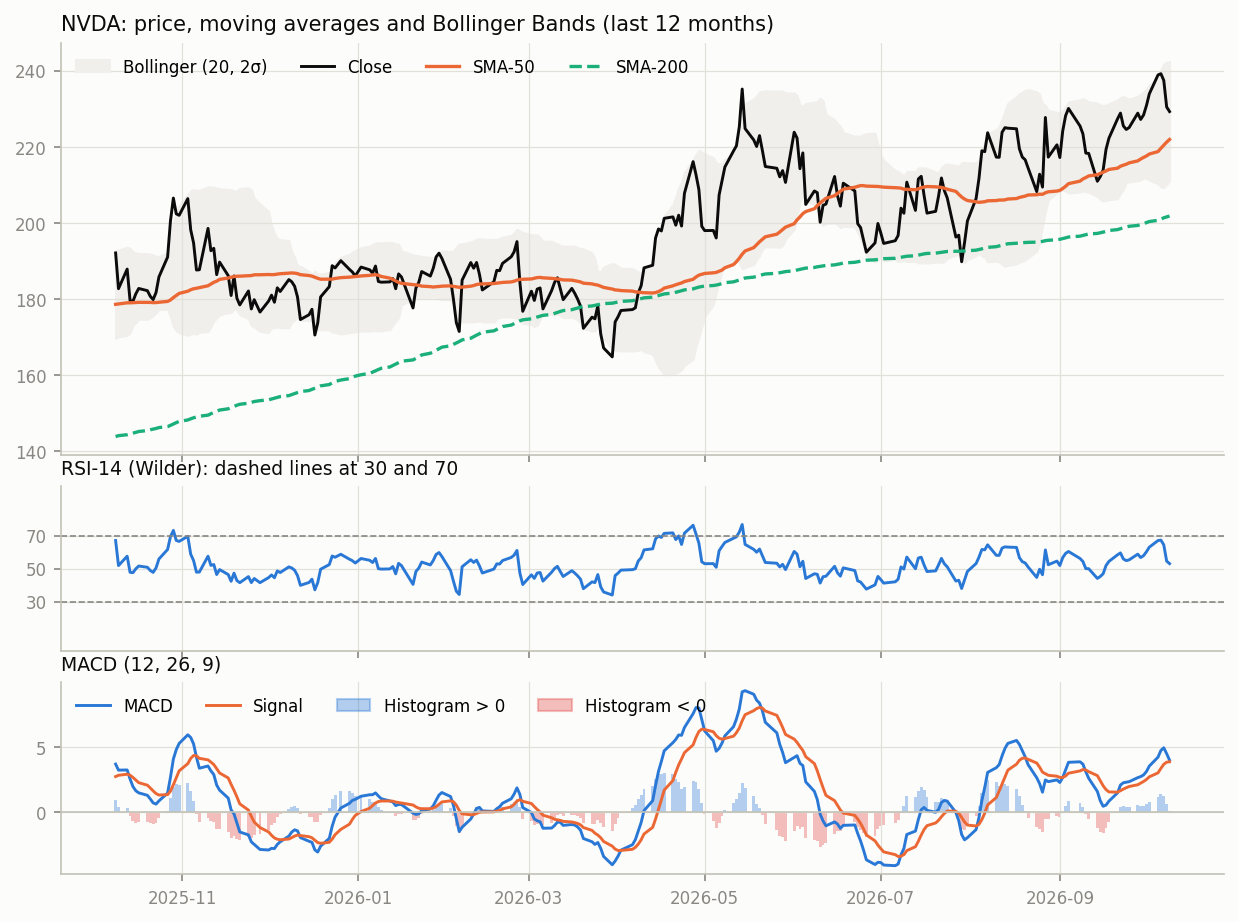

In [22]:
from IPython.display import HTML
print(json.dumps(result["report_paths"], indent=2))
HTML(open(result["report_paths"]["html"], encoding="utf-8").read())

In [23]:
# Colab only: download the outputs folder, then commit it to task1_financial/outputs/
if "google.colab" in sys.modules:
    from google.colab import files
    !zip -q -r outputs.zip outputs
    files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Appendix: every prompt (defined as constants in `prompts.py`)

In [24]:
from equity_research.prompts import all_prompts
for name, text in all_prompts().items():
    print(f"===== {name} =====\n{text}\n")

===== HEADLINE_SYSTEM =====
You classify ONE news headline by its likely effect on the share price of {ticker} ({company}) over the next days to weeks.

Labels:
- positive: likely to push {ticker} up (earnings beat, upgrade, big contract, favourable ruling)
- negative: likely to push {ticker} down (earnings miss, downgrade, lawsuit, recall, key executive leaves)
- neutral: no clear price effect, or mainly about another company or the whole market

Rules:
- Judge only the headline text. Do not assume facts that are not in it.
- A headline about a competitor or supplier is neutral unless it clearly affects {ticker}.
- confidence: 0.9 or more only if the effect is direct and obvious; 0.5-0.7 if it depends on missing details; below 0.5 if guessing.
- brief_reason: one sentence, at most 25 words.

Reply with ONLY a JSON object, no other text:
{{"headline": "<copied exactly>", "sentiment": "positive|negative|neutral", "confidence": <0-1>, "brief_reason": "<one sentence>"}}

===== HEADLINE_HU